## Setup
Environment, imports, configuration printout. Nothing here changes any data.

In [1]:
import sys, subprocess
import os

In [2]:
import sys, os
print(sys.executable)      # the python being used right now
print(sys.prefix)          # the environment folder
print(sys.version)
print(os.environ.get("VIRTUAL_ENV"), os.environ.get("CONDA_DEFAULT_ENV"))

/home/aa8624/thesis_2500/venv/bin/python
/home/aa8624/thesis_2500/venv
3.12.3 (main, Mar 23 2026, 19:04:32) [GCC 13.3.0]
None None


In [3]:
# List the key package versions in this environment 
print("python:", sys.executable)
print(subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
      .split("\n")[0:0] or "")
out = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
print("\n".join(l for l in out.splitlines() if l.lower().split()[0:1] and l.lower().split()[0] in
      ("torch", "torchvision", "torchaudio", "transformers", "huggingface-hub", "open_clip_torch", "open-clip-torch")))

python: /home/aa8624/thesis_2500/venv/bin/python

open_clip_torch           3.3.0
torch                     2.11.0+cu128
torchvision               0.26.0+cu128
transformers              5.13.0


In [ ]:
#Pick the GPU (index from nvidia-smi)
os.environ["CUDA_VISIBLE_DEVICES"] = "3"   

In [5]:
# Imports and config printout. 
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))         
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import size_config as sc
import config
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler

%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)


print("PROJECT_ROOT :", config.PROJECT_ROOT)
print("QUICK_RUN    :", config.QUICK_RUN, "  (True = tiny settings, NOT for final results)")
print("family set   :", config.ACTIVE_FAMILY_SET, "| models:", config.MODELS_TO_RUN)
print("seeds        :", config.EXPERIMENT_SEEDS)
try:
    import torch; print("torch        :", torch.__version__, "| CUDA:", torch.cuda.is_available())
except ImportError:
    print("torch not installed (only the logistic-regression models will work)")

PROJECT_ROOT : /data/aa8624/thesis_2500
QUICK_RUN    : False   (True = tiny settings, NOT for final results)
family set   : diffusion_split | models: ['spectral_lr', 'handcrafted_lr', 'lbp_lr', 'cnn_densenet', 'supcon', 'npr', 'clip_frozen', 'biomedclip_frozen', 'rad_dino', 'dinov2_frozen']
seeds        : [42, 43, 44]
torch        : 2.11.0+cu128 | CUDA: True


In [6]:
# Number of data-loader workers for the CNN detectors
config.CNN_NUM_WORKERS = 4

In [7]:
# One-off environment fixes. Execute only once.
!{sys.executable} -m pip uninstall -y huggingface-hub
!{sys.executable} -m pip install "huggingface-hub>=1.5,<2.0"
%pip install open_clip_torch

Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)


Note: you may need to restart the kernel to use updated packages.


### Sensitivity to preprocessing

#### (i) Provenance control

In [ ]:
import importlib
from evaluation import provenance_control as pc
importlib.reload(pc)
Rp = pc.run(models=None, B=1000)
Gp = pc.summarise(Rp)
print(Rp.groupby(["model", "train"]).size().unstack())    

        IP-trained biomedclip_frozen seed 42: direct=0.50  via512=0.50  updown=0.52


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

        IP-trained      clip_frozen seed 42: direct=0.50  via512=0.48  updown=0.46
        IP-trained     cnn_densenet seed 42: direct=0.50  via512=0.49  updown=0.57
        IP-trained     cnn_densenet seed 43: direct=0.50  via512=0.50  updown=0.57
        IP-trained     cnn_densenet seed 44: direct=0.50  via512=0.49  updown=0.58


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

        IP-trained    dinov2_frozen seed 42: direct=0.50  via512=0.50  updown=0.47
        IP-trained   handcrafted_lr seed 42: direct=0.50  via512=0.48  updown=0.83
        IP-trained           lbp_lr seed 42: direct=0.50  via512=0.47  updown=0.70
        IP-trained              npr seed 42: direct=0.50  via512=0.49  updown=0.46
        IP-trained              npr seed 43: direct=0.50  via512=0.49  updown=0.44
        IP-trained              npr seed 44: direct=0.50  via512=0.48  updown=0.50


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

        IP-trained         rad_dino seed 42: direct=0.50  via512=0.50  updown=0.50
        IP-trained      spectral_lr seed 42: direct=0.50  via512=0.47  updown=0.87
        IP-trained           supcon seed 42: direct=0.50  via512=0.49  updown=0.56
        IP-trained           supcon seed 43: direct=0.50  via512=0.49  updown=0.56
        IP-trained           supcon seed 44: direct=0.50  via512=0.49  updown=0.59
 Diffusion-trained biomedclip_frozen seed 42: direct=0.50  via512=0.49  updown=0.66
 Diffusion-trained      clip_frozen seed 42: direct=0.50  via512=0.51  updown=0.50
 Diffusion-trained     cnn_densenet seed 42: direct=0.50  via512=0.47  updown=0.92
 Diffusion-trained     cnn_densenet seed 43: direct=0.50  via512=0.48  updown=0.87
 Diffusion-trained     cnn_densenet seed 44: direct=0.50  via512=0.48  updown=0.86
 Diffusion-trained    dinov2_frozen seed 42: direct=0.50  via512=0.51  updown=0.45
 Diffusion-trained   handcrafted_lr seed 42: direct=0.50  via512=0.48  updown=0.84
 Di

#### (ii) JPEG-quality sensitivity

In [ ]:
import importlib, config
from evaluation import sensitivity_check as sn
importlib.reload(sn)
out = sn.run("q75")                                                       
out = sn.run("q75_all", overrides=config.SENSITIVITY_VARIANTS["q75"],
             models=config.SENSITIVITY_MODELS_ALL, n_jobs=1)             
out = sn.run("noharm")                                                    
out["summary"]

variant: q75 {'PREP_JPEG_QUALITY': 75} -> /data/aa8624/thesis_2500/sensitivity/q75
  prepared 500/19973
  prepared 1000/19973
  prepared 1500/19973
  prepared 2000/19973
  prepared 2500/19973
  prepared 3000/19973
  prepared 3500/19973
  prepared 4000/19973
  prepared 4500/19973
  prepared 5000/19973
  prepared 5500/19973
  prepared 6000/19973
  prepared 6500/19973
  prepared 7000/19973
  prepared 7500/19973
  prepared 8000/19973
  prepared 8500/19973
  prepared 9000/19973
  prepared 9500/19973
  prepared 10000/19973
  prepared 10500/19973
  prepared 11000/19973
  prepared 11500/19973
  prepared 12000/19973
  prepared 12500/19973
  prepared 13000/19973
  prepared 13500/19973
  prepared 14000/19973
  prepared 14500/19973
  prepared 15000/19973
  prepared 15500/19973
  prepared 16000/19973
  prepared 16500/19973
  prepared 17000/19973
  prepared 17500/19973
  prepared 18000/19973
  prepared 18500/19973
  prepared 19000/19973
  prepared 19500/19973
Prepared 19973 images (19973 new) -> /da

[33/60] Diffusion->Diffusion_EditOnly lbp_lr             seed=42 -> AUROC in=0.706 cross=0.521 (0s) | elapsed 2.8 min
[34/60] Diffusion->Diffusion_Reconstruction spectral_lr        seed=42 -> AUROC in=0.723 cross=0.670 (0s) | elapsed 2.9 min
[35/60] Diffusion->Diffusion_Reconstruction handcrafted_lr     seed=42 -> AUROC in=0.732 cross=0.688 (0s) | elapsed 3.0 min
[36/60] Diffusion->Diffusion_Reconstruction lbp_lr             seed=42 -> AUROC in=0.706 cross=0.687 (0s) | elapsed 3.1 min
[37/60] Diffusion_EditOnly->IP       spectral_lr        seed=42 -> AUROC in=0.585 cross=0.589 (0s) | elapsed 3.2 min
[38/60] Diffusion_EditOnly->IP       handcrafted_lr     seed=42 -> AUROC in=0.567 cross=0.620 (0s) | elapsed 3.3 min
[39/60] Diffusion_EditOnly->IP       lbp_lr             seed=42 -> AUROC in=0.523 cross=0.580 (0s) | elapsed 3.3 min
[40/60] Diffusion_EditOnly->CycleGAN spectral_lr        seed=42 -> AUROC in=0.585 cross=0.475 (0s) | elapsed 3.4 min
[41/60] Diffusion_EditOnly->CycleGAN handc

[1/180] IP->CycleGAN                 spectral_lr        seed=42 -> AUROC in=0.726 cross=0.327 (0s) | elapsed 0.1 min
[2/180] IP->CycleGAN                 handcrafted_lr     seed=42 -> AUROC in=0.701 cross=0.318 (0s) | elapsed 0.2 min
[3/180] IP->CycleGAN                 lbp_lr             seed=42 -> AUROC in=0.594 cross=0.281 (0s) | elapsed 0.3 min
[4/180] IP->CycleGAN                 cnn_densenet       seed=42 -> AUROC in=0.993 cross=0.552 (679s) | elapsed 11.9 min
[5/180] IP->CycleGAN                 npr                seed=42 -> AUROC in=0.940 cross=0.490 (384s) | elapsed 18.6 min
    [clip_frozen] embedding 3000 new / changed images ...
    [clip_frozen] embedding 1000 new / changed images ...
    [clip_frozen] embedding 1000 new / changed images ...
    [clip_frozen] embedding 500 new / changed images ...
[6/180] IP->CycleGAN                 clip_frozen        seed=42 -> AUROC in=0.878 cross=0.620 (227s) | elapsed 23.0 min
    [biomedclip_frozen] embedding 3000 new / changed image

[52/180] CycleGAN->Diffusion          biomedclip_frozen  seed=42 -> AUROC in=0.794 cross=0.542 (14s) | elapsed 62.4 min
[53/180] CycleGAN->Diffusion          dinov2_frozen      seed=42 -> AUROC in=0.977 cross=0.717 (9s) | elapsed 62.7 min
[54/180] CycleGAN->Diffusion          rad_dino           seed=42 -> AUROC in=0.814 cross=0.628 (20s) | elapsed 63.1 min
[55/180] CycleGAN->Diffusion_EditOnly spectral_lr        seed=42 -> AUROC in=0.697 cross=0.479 (0s) | elapsed 63.1 min
[56/180] CycleGAN->Diffusion_EditOnly handcrafted_lr     seed=42 -> AUROC in=0.829 cross=0.495 (0s) | elapsed 63.2 min
[57/180] CycleGAN->Diffusion_EditOnly lbp_lr             seed=42 -> AUROC in=0.828 cross=0.495 (0s) | elapsed 63.3 min
[58/180] CycleGAN->Diffusion_EditOnly cnn_densenet       seed=42 -> AUROC in=1.000 cross=0.523 (127s) | elapsed 65.6 min
[59/180] CycleGAN->Diffusion_EditOnly npr                seed=42 -> AUROC in=0.996 cross=0.493 (76s) | elapsed 67.0 min
[60/180] CycleGAN->Diffusion_EditOnly clip_

    [biomedclip_frozen] embedding 500 new / changed images ...
[115/180] Diffusion_EditOnly->IP       biomedclip_frozen  seed=42 -> AUROC in=0.670 cross=0.752 (18s) | elapsed 102.3 min
    [dinov2_frozen] embedding 1495 new / changed images ...
    [dinov2_frozen] embedding 500 new / changed images ...
[116/180] Diffusion_EditOnly->IP       dinov2_frozen      seed=42 -> AUROC in=0.624 cross=0.650 (16s) | elapsed 102.7 min
    [rad_dino] embedding 1495 new / changed images ...
    [rad_dino] embedding 500 new / changed images ...
[117/180] Diffusion_EditOnly->IP       rad_dino           seed=42 -> AUROC in=0.727 cross=0.808 (23s) | elapsed 103.1 min
[118/180] Diffusion_EditOnly->CycleGAN spectral_lr        seed=42 -> AUROC in=0.585 cross=0.475 (0s) | elapsed 103.2 min
[119/180] Diffusion_EditOnly->CycleGAN handcrafted_lr     seed=42 -> AUROC in=0.567 cross=0.387 (0s) | elapsed 103.3 min
[120/180] Diffusion_EditOnly->CycleGAN lbp_lr             seed=42 -> AUROC in=0.523 cross=0.327 (0s) 

[174/180] Diffusion_Reconstruction->Diffusion_EditOnly lbp_lr             seed=42 -> AUROC in=0.730 cross=0.516 (0s) | elapsed 140.5 min
[175/180] Diffusion_Reconstruction->Diffusion_EditOnly cnn_densenet       seed=42 -> AUROC in=0.980 cross=0.661 (167s) | elapsed 143.5 min
[176/180] Diffusion_Reconstruction->Diffusion_EditOnly npr                seed=42 -> AUROC in=0.926 cross=0.601 (99s) | elapsed 145.3 min
[177/180] Diffusion_Reconstruction->Diffusion_EditOnly clip_frozen        seed=42 -> AUROC in=0.828 cross=0.555 (35s) | elapsed 146.0 min
[178/180] Diffusion_Reconstruction->Diffusion_EditOnly biomedclip_frozen  seed=42 -> AUROC in=0.731 cross=0.594 (11s) | elapsed 146.2 min
[179/180] Diffusion_Reconstruction->Diffusion_EditOnly dinov2_frozen      seed=42 -> AUROC in=0.857 cross=0.575 (19s) | elapsed 146.6 min
[180/180] Diffusion_Reconstruction->Diffusion_EditOnly rad_dino           seed=42 -> AUROC in=0.683 cross=0.543 (21s) | elapsed 147.1 min

Finished: 180 run(s) executed, 0 

[1/60] IP->CycleGAN                 spectral_lr        seed=42 -> AUROC in=0.704 cross=0.599 (0s) | elapsed 0.1 min
[2/60] IP->CycleGAN                 handcrafted_lr     seed=42 -> AUROC in=0.718 cross=0.505 (0s) | elapsed 0.2 min
[3/60] IP->CycleGAN                 lbp_lr             seed=42 -> AUROC in=0.624 cross=0.401 (0s) | elapsed 0.2 min
[4/60] IP->Diffusion                spectral_lr        seed=42 -> AUROC in=0.704 cross=0.792 (0s) | elapsed 0.3 min
[5/60] IP->Diffusion                handcrafted_lr     seed=42 -> AUROC in=0.718 cross=0.779 (0s) | elapsed 0.4 min
[6/60] IP->Diffusion                lbp_lr             seed=42 -> AUROC in=0.624 cross=0.761 (0s) | elapsed 0.5 min
[7/60] IP->Diffusion_EditOnly       spectral_lr        seed=42 -> AUROC in=0.704 cross=0.621 (0s) | elapsed 0.6 min
[8/60] IP->Diffusion_EditOnly       handcrafted_lr     seed=42 -> AUROC in=0.718 cross=0.615 (0s) | elapsed 0.7 min
[9/60] IP->Diffusion_EditOnly       lbp_lr             seed=42 -> AUROC 

original   variant  mean_diff  max_abs_diff  rank_corr
model          role                                                              
handcrafted_lr test_cross  0.608789  0.617262   0.008473      0.104936   0.965414
               test_in     0.794510  0.779493  -0.015017      0.064105   1.000000
lbp_lr         test_cross  0.582483  0.620026   0.037542      0.266464   0.798496
               test_in     0.751945  0.771952   0.020007      0.033165   1.000000
spectral_lr    test_cross  0.675722  0.673304  -0.002418      0.064116   0.950376
               test_in     0.771938  0.771594  -0.000344      0.048288   1.000000

In [ ]:
import importlib, config
from evaluation import sensitivity_check as sn
importlib.reload(sn)

out_supcon = sn.run(
    "q75_supcon",                              
    overrides=config.SENSITIVITY_VARIANTS["q75"],   
    models=["supcon"],
    n_jobs=1,
)
out_supcon["summary"]          
out_supcon["by_test_family"]

variant: q75_supcon {'PREP_JPEG_QUALITY': 75} -> /data/aa8624/thesis_2500/sensitivity/q75_supcon
  prepared 500/19973
  prepared 1000/19973
  prepared 1500/19973
  prepared 2000/19973
  prepared 2500/19973
  prepared 3000/19973
  prepared 3500/19973
  prepared 4000/19973
  prepared 4500/19973
  prepared 5000/19973
  prepared 5500/19973
  prepared 6000/19973
  prepared 6500/19973
  prepared 7000/19973
  prepared 7500/19973
  prepared 8000/19973
  prepared 8500/19973
  prepared 9000/19973
  prepared 9500/19973
  prepared 10000/19973
  prepared 10500/19973
  prepared 11000/19973
  prepared 11500/19973
  prepared 12000/19973
  prepared 12500/19973
  prepared 13000/19973
  prepared 13500/19973
  prepared 14000/19973
  prepared 14500/19973
  prepared 15000/19973
  prepared 15500/19973
  prepared 16000/19973
  prepared 16500/19973
  prepared 17000/19973
  prepared 17500/19973
  prepared 18000/19973
  prepared 18500/19973
  prepared 19000/19973
  prepared 19500/19973
Prepared 19973 images (199

,original,variant,diff
test,,,
CycleGAN,0.712,0.503,-0.208
Diffusion,0.870,0.813,-0.057
Diffusion_EditOnly,0.638,0.600,-0.038
Diffusion_Reconstruction,0.736,0.695,-0.041
IP,0.705,0.638,-0.067


#### Robustness to unseen alterations

#### (i) Local blur control

In [ ]:
from evaluation import smoothness_controls as sm
importlib.reload(sm)
resD = sm.run_all(models=None, which="D")
print(resD["D"].groupby(["model", "train"]).size().unstack())    

Real images: 2500 (train/val/test = 1500/500/500)

Calibration of blur strength by spectral slope (median over real train images):
  blur sigma -> {0.3: -3.098, 0.5: -3.603, 0.7: -4.213, 1.0: -4.669, 1.5: -4.889, 2.0: -4.784, 3.0: -4.345}
  target group medians: {'Diffusion_Reconstruction': -3.221, 'CycleGAN': -3.021, 'Diffusion': -3.253, 'Real': -3.064}
  chosen sigma: {'Diffusion_Reconstruction': 0.3, 'CycleGAN': 0.3, 'Diffusion': 0.3} (if a chosen sigma sits at the edge of the grid, widen `grid`)

=== D. blur only a patch of a real image (local smoothing, no generator) ===
  D        IP-trained biomedclip_frozen seed 42: 0.5%=0.51  1%=0.55  2%=0.60  5%=0.72  10%=0.85
  D        IP-trained      clip_frozen seed 42: 0.5%=0.58  1%=0.69  2%=0.80  5%=0.89  10%=0.94
  D        IP-trained     cnn_densenet seed 42: 0.5%=0.69  1%=0.85  2%=0.93  5%=0.99  10%=1.00
  D        IP-trained    dinov2_frozen seed 42: 0.5%=0.55  1%=0.58  2%=0.66  5%=0.83  10%=0.90
  D        IP-trained   handcrafted_

In [9]:
from evaluation import smoothness_controls2 as s2
importlib.reload(s2)
resD2 = s2.run_extra(models=None, which="D2")


=== D2. patch of a REAL test image altered in different ways (no generator) ===
  scored        IP-trained biomedclip_frozen seed 42
  scored        IP-trained      clip_frozen seed 42
  scored        IP-trained     cnn_densenet seed 42
  scored        IP-trained    dinov2_frozen seed 42
  scored        IP-trained   handcrafted_lr seed 42
  scored        IP-trained           lbp_lr seed 42
  scored        IP-trained              npr seed 42
  scored        IP-trained         rad_dino seed 42
  scored        IP-trained      spectral_lr seed 42
  scored        IP-trained           supcon seed 42
  scored Diffusion-trained biomedclip_frozen seed 42
  scored Diffusion-trained      clip_frozen seed 42
  scored Diffusion-trained     cnn_densenet seed 42
  scored Diffusion-trained    dinov2_frozen seed 42
  scored Diffusion-trained   handcrafted_lr seed 42
  scored Diffusion-trained           lbp_lr seed 42
  scored Diffusion-trained              npr seed 42
  scored Diffusion-trained       

#### (ii) JPEG compression shift

In [ ]:
import time
import pandas as pd
from experiments import ladder_scoring as ls
from evaluation import compression_ladder as cl

t0 = time.time()
res = cl.run(quality=75, B=500)                 
U, S, M = cl.compare(res, quality=75, thr=0.70)
print(f"\ntook {(time.time() - t0) / 60:.0f} min")

# sanity: the clean file route should reproduce the saved ladder
old = pd.read_csv(ls.OUT_DIR / "ladder_results.csv")
j = res["clean_files"].merge(old, on=["train", "detector", "group", "level"], suffixes=("_new", "_old"))
print("max |clean file route - saved ladder| AUROC:", (j["auroc_new"] - j["auroc_old"]).abs().max().round(4))

# results
print("\nSmallest flagged area (best detector) and number of detectors reaching it, clean vs q75:")
print(S)
print("\nMean AUROC by train x series x area, clean vs q75:")
print(M.round(3).to_string())

# save for the report
out = cl.OUT
S.to_csv(out / "min_area_clean_vs_q75.csv")
M.to_csv(out / "mean_auroc_clean_vs_q75.csv")
U.to_csv(out / "min_area_per_detector.csv")
print("\nsaved to", out)

500 real test images, 12287 ladder images, 500 bootstrap draws (cluster=subject_id), 484 images per draw
IP-trained / spectral_lr: 1 seed(s) done
  scored clean_files: IP__to__CycleGAN handcrafted_lr seed 42
IP-trained / handcrafted_lr: 1 seed(s) done
  scored clean_files: IP__to__CycleGAN lbp_lr seed 42
IP-trained / lbp_lr: 1 seed(s) done
  scored clean_files: IP__to__CycleGAN cnn_densenet seed 42
  scored clean_files: IP__to__CycleGAN cnn_densenet seed 43
  scored clean_files: IP__to__CycleGAN cnn_densenet seed 44
IP-trained / cnn_densenet: 3 seed(s) done
  scored clean_files: IP__to__CycleGAN supcon seed 42
  scored clean_files: IP__to__CycleGAN supcon seed 43
  scored clean_files: IP__to__CycleGAN supcon seed 44
IP-trained / supcon: 3 seed(s) done
  scored clean_files: IP__to__CycleGAN npr seed 42
  scored clean_files: IP__to__CycleGAN npr seed 43
  scored clean_files: IP__to__CycleGAN npr seed 44
IP-trained / npr: 3 seed(s) done
  scored clean_files: IP__to__CycleGAN clip_frozen s

EditOnly-trained / rad_dino: 1 seed(s) done
  scored q75: Diffusion_EditOnly__to__IP dinov2_frozen seed 42
EditOnly-trained / dinov2_frozen: 1 seed(s) done

took 72 min
max |clean file route - saved ladder| AUROC: 0.0

Smallest flagged area (best detector) and number of detectors reaching it, clean vs q75:
                                        clean_best  clean_n    q_best  q_n
train             group                                                   
Diffusion-trained Diffusion_paste         0.050006        6  0.100004    1
                  IP_Blob                 0.050116        1  0.050116    1
                  IP_CopyMove             0.019775        8  0.019775    1
                  IP_TextureTransplant    0.019775        7  0.049576    1
EditOnly-trained  Diffusion_paste         0.020003        9  0.050006    5
                  IP_Blob                 0.019871        8  0.019871    5
                  IP_CopyMove             0.019775       10  0.019775    4
                 

#### Needed for report

In [ ]:
import numpy as np, pandas as pd, config

# ---------- load ----------
d = pd.read_csv(config.DET_RESULTS_CSV)                                   
L = pd.read_csv(config.DET_RESULTS_DIR / "ladder_scoring" / "ladder_results.csv")
print("ladder columns:", L.columns.tolist(), "| rows:", len(L))

m = {"Diffusion_EditOnly": "EditOnly", "Diffusion_Reconstruction": "Reconstruction"}
d["train_family"] = d["train_family"].replace(m)
d["test_family"] = d["test_family"].replace(m)

# column names in the ladder file (adjust here if the print above shows different ones)
tcol = next(c for c in ("train", "train_family", "trained_on") if c in L.columns)
dcol = next(c for c in ("detector", "model") if c in L.columns)
assert {"group", "level", "auroc", "auroc_lo", "auroc_hi"} <= set(L.columns), "missing columns"

L["train_family"] = L[tcol].astype(str).str.replace("-trained", "", regex=False)
L["pct"] = (L["level"].astype(str).str[1:].str.replace("p", ".", regex=False)).astype(float)   # 0.5, 1, 2, 5, 10

# one row per detector x training family x series x level (average seeds if any remain)
key = ["train_family", dcol, "group", "pct"]
if L.duplicated(key).any():
    print("duplicate rows found: averaging them (check that these are seeds)")
    L = L.groupby(key, as_index=False)[["auroc", "auroc_lo", "auroc_hi"]].mean()

# ---------- check 1: interval half-widths ----------
hw = (L["auroc_hi"] - L["auroc_lo"]) / 2
print(f"\nhalf-width: mean {hw.mean():.3f}, max {hw.max():.3f}, n = {len(hw)} (table says 0.016 / 0.041, 750)")

# ---------- check 2: Diffusion-full rows with the reconstruction baseline ----------
cr = (d[d.role == "test_cross"].query("test_family == 'Reconstruction'")
        .groupby(["model", "train_family"])["auroc"].mean())              # baseline per detector x training family

F = L[L.group == "Diffusion_full"].copy()
F["b"] = [cr[(det, t)] for det, t in zip(F[dcol], F["train_family"])]
F["ok"] = (F.auroc >= 0.70) & (F.auroc_lo > F.b)

expected = {"IP": "2 / 3 / 6 / 4, best 0.5", "EditOnly": "7 / 9 / 10 / 0, best 0.5", "Diffusion": "10 / 10 / 10 / 0, best 0.5"}
print("\nDiffusion full, baseline = Reconstruction AUROC:")
for t, g in F.groupby("train_family"):
    n_det = g[dcol].nunique()
    first = g[g.ok].groupby(dcol)["pct"].min()
    c2, c5, c10 = (first <= 2).sum(), (first <= 5).sum(), (first <= 10).sum()
    best = first.min() if len(first) else None
    print(f"  {t:<10} <=2%: {c2}  <=5%: {c5}  <=10%: {c10}  never: {n_det - c10}  best: {best}%"
          f"   | table: {expected.get(t)}")
    print("     first area per detector:", first.sort_values().to_dict())

ladder columns: ['train', 'slug', 'detector', 'group', 'level', 'area', 'n', 'n_seeds', 'auroc', 'auroc_lo', 'auroc_hi', 'boot_bias', 'win', 'win_lo', 'win_hi', 'seed_sd'] | rows: 750

half-width: mean 0.016, max 0.041, n = 750 (table says 0.016 / 0.041, 750)

Diffusion full, baseline = Reconstruction AUROC:
  Diffusion  <=2%: 10  <=5%: 10  <=10%: 10  never: 0  best: 0.5%   | table: 10 / 10 / 10 / 0, best 0.5
     first area per detector: {'biomedclip_frozen': 0.5, 'clip_frozen': 0.5, 'cnn_densenet': 0.5, 'dinov2_frozen': 0.5, 'handcrafted_lr': 0.5, 'lbp_lr': 0.5, 'npr': 0.5, 'supcon': 0.5, 'rad_dino': 2.0, 'spectral_lr': 2.0}
  EditOnly   <=2%: 7  <=5%: 9  <=10%: 10  never: 0  best: 0.5%   | table: 7 / 9 / 10 / 0, best 0.5
     first area per detector: {'lbp_lr': 0.5, 'npr': 0.5, 'handcrafted_lr': 0.5, 'supcon': 0.5, 'spectral_lr': 1.0, 'biomedclip_frozen': 2.0, 'cnn_densenet': 2.0, 'clip_frozen': 5.0, 'rad_dino': 5.0, 'dinov2_frozen': 10.0}
  IP         <=2%: 2  <=5%: 3  <=10%: 6  ne

In [9]:
import json, re, pathlib, config

root = pathlib.Path(config.__file__).resolve().parent          # folder that holds config.py
patterns = {
    "no-edit band / footprint report": r"footprint_report|null.*footprint|footprint.*null",
    "family-level AUROC":              r"family.*auroc|auroc.*family|family_auc|by_family",
    "seed averaging / bootstrap":      r"n_seeds|seed_sd|cluster|boot_bias|n_boot",
}

def sources(path):
    if path.suffix == ".py":
        yield path.name, path.read_text(errors="ignore")
    elif path.suffix == ".ipynb":
        nb = json.loads(path.read_text(errors="ignore"))
        for i, c in enumerate(nb.get("cells", [])):
            if c.get("cell_type") == "code":
                yield f"{path.name} [cell {i}]", "".join(c.get("source", []))

hits = {k: [] for k in patterns}
for p in list(root.rglob("*.py")) + list(root.rglob("*.ipynb")):
    if ".ipynb_checkpoints" in str(p) or "site-packages" in str(p):
        continue
    for name, text in sources(p):
        for label, pat in patterns.items():
            if re.search(pat, text, flags=re.I):
                hits[label].append((name, text))

for label, items in hits.items():
    print("=" * 80, "\n", label, "->", [n for n, _ in items][:12])
    for name, text in items[:2]:                                # first two matches per topic
        print("-" * 80, "\n#", name)
        print("\n".join(text.splitlines()[:70]))                # first 70 lines of each match

 no-edit band / footprint report -> ['footprint.py', 'footprint.py', 'ladder_frequency.py', 'Size Ladder Experiment.ipynb [cell 50]', 'Size Ladder Experiment.ipynb [cell 62]', 'Size Ladder Experiment.ipynb [cell 63]', 'main.ipynb [cell 160]', 'main.ipynb [cell 161]', 'main.ipynb [cell 162]', 'B_20Oct2026_main.ipynb [cell 106]', 'B_20Oct2026_main.ipynb [cell 111]', 'B_20Oct2026_main.ipynb [cell 114]']
-------------------------------------------------------------------------------- 
# footprint.py
"""
Stage 3 / 6 / 7 - FOOTPRINT and SHIFT DIRECTION of a family or an edit level in the 42-feature space.

shift vector  = (mean feature vector of the images  -  mean of Real_Untouched TRAIN)  /  std of Real_Untouched TRAIN
footprint     = length of the shift vector (how far the family sits from real images, in real-image standard deviations)
direction     = the shift vector's orientation; cosine similarity compares directions between families / levels
null          = footprint of Real_Source (

In [10]:
import re, json, pathlib, config
root = pathlib.Path(config.__file__).resolve().parent

def show(fname, pat, ctx=6, maxhits=4):
    for p in root.rglob(fname):
        if "site-packages" in str(p) or ".ipynb_checkpoints" in str(p): continue
        L = p.read_text(errors="ignore").splitlines()
        hits = [i for i, l in enumerate(L) if re.search(pat, l, re.I)]
        print("=" * 90, "\n", p.name, "| matches:", len(hits))
        last = -99
        for i in hits[:maxhits * 3]:
            if i - last < ctx: continue
            print("-" * 60, f"line {i+1}")
            print("\n".join(L[max(0, i - ctx): i + ctx + 1]))
            last = i

# 1. seed combining + bootstrap in the ladder scoring script
show("ladder_scoring.py", r"seed|boot|cluster|subject|groupby|mean\(")

# 2. footprint call (B used) and any feature-family AUROC in the ladder script
show("ladder_frequency.py", r"real_null|ladder_footprints|B=|family|auroc|LogisticRegression")

# 3. where the 0.55-0.63 numbers might come from
show("config.py", r"FEATURE_FAMIL|FEATURE_GROUP|FAMILY_SETS|LADDER.*(SEED|BOOT)|BOOT")

 ladder_scoring.py | matches: 53
------------------------------------------------------------ line 8
STAGE 4d - SIZE-LADDER SCORING (cross-model experiment)   (file: stage4_experiments/ladder_scoring.py)
Question: detectors trained ONCE in the main experiment (on the 5% base edits) are scored, unchanged, on the
ladder test images (0.5 - 10% edit area). How does detectability change with edit size?

Nothing is retrained and no main result file is touched. Detectors are loaded from
    config.DET_MODEL_DIR / <train slug> / <model>_seed<seed>          (needs SAVE_FITTED_MODELS=True in the grid run)

DESIGN (single Real set)
    positives   ladder images of the TEST split (one per source image and level), from the Stage 3 ladder table
    negatives   the Real TEST images of the modelling table. Every positive was made from one of them, so each
                edited image has its unedited source among the negatives. The "no-edit floor" is therefore 0.5
                by construction (ther

### Soft mask check

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))                  
sys.path.insert(0, str(Path.cwd() / "evaluation"))   

import soft_mask_check as smc
res = smc.run(n_per_level=40)

  series level  n         sumA_over_M           out_share          in_partial               area_pct            sigma_px                 iou
EditOnly  d0p5 40 1.000 (1.000-1.000) 0.038 (0.036-0.038) 0.392 (0.392-0.407)    0.501 (0.501-0.501) 0.799 (0.799-0.799)                 NaN
EditOnly    d1 40 1.000 (1.000-1.000) 0.045 (0.045-0.046) 0.350 (0.347-0.350)    1.001 (1.001-1.001) 1.129 (1.129-1.129)                 NaN
EditOnly    d2 40 1.000 (1.000-1.000) 0.050 (0.049-0.053) 0.343 (0.335-0.367)    2.000 (2.000-2.001) 1.596 (1.596-1.596)                 NaN
EditOnly    d5 40 1.000 (1.000-1.000) 0.059 (0.055-0.077) 0.352 (0.332-0.395)    5.001 (5.000-5.001) 2.523 (2.523-2.523)                 NaN
EditOnly   d10 40 1.000 (1.000-1.000) 0.085 (0.060-0.105) 0.456 (0.343-0.578) 10.000 (10.000-10.001) 3.568 (3.568-3.568)                 NaN
    Blob  a0p5 40 0.832 (0.828-0.833) 0.008 (0.007-0.008) 0.467 (0.463-0.472)    0.490 (0.485-0.494)                 NaN 0.994 (0.985-1.000)
    Blob    a

#### edit size ladder visualisation

In [ ]:
import os, sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))                       

import config
os.environ["CXR_PROJECT_ROOT"] = str(config.PROJECT_ROOT)  

import importlib
import utils.make_edit_figures_v2 as mef
importlib.reload(mef)                                      

# mef.STEM = "0e20be62-bb9be4b9-f8b81599-46a72bfd-377caad1"
mef.STEM = "13749b4f-8d28e080-49f5ddbd-bb9afa3d-e86d4f31"
# mef.FIG_LEVEL = "5"
# mef.N_STATS = 100

mef.main()

image id: 13749b4f-8d28e080-49f5ddbd-bb9afa3d-e86d4f31
saved figures_edits/fig_gallery.pdf
saved figures_edits/fig_pipeline.pdf
EditOnly           inside  12.60  outside   0.02  (grey levels, n=100)
Diffusion (full)   inside  13.06  outside   2.36  (grey levels, n=100)
Reconstruction     inside   2.78  outside   1.87  (grey levels, n=100)
saved figures_edits/fig_vae_trace.pdf
enlarged crops (mask did not fit; say so in the caption): ['EditOnly 10%']
saved figures_edits/fig_ladder_crops.pdf
saved figures_edits/fig_ladder_full.pdf


fig_pipeline


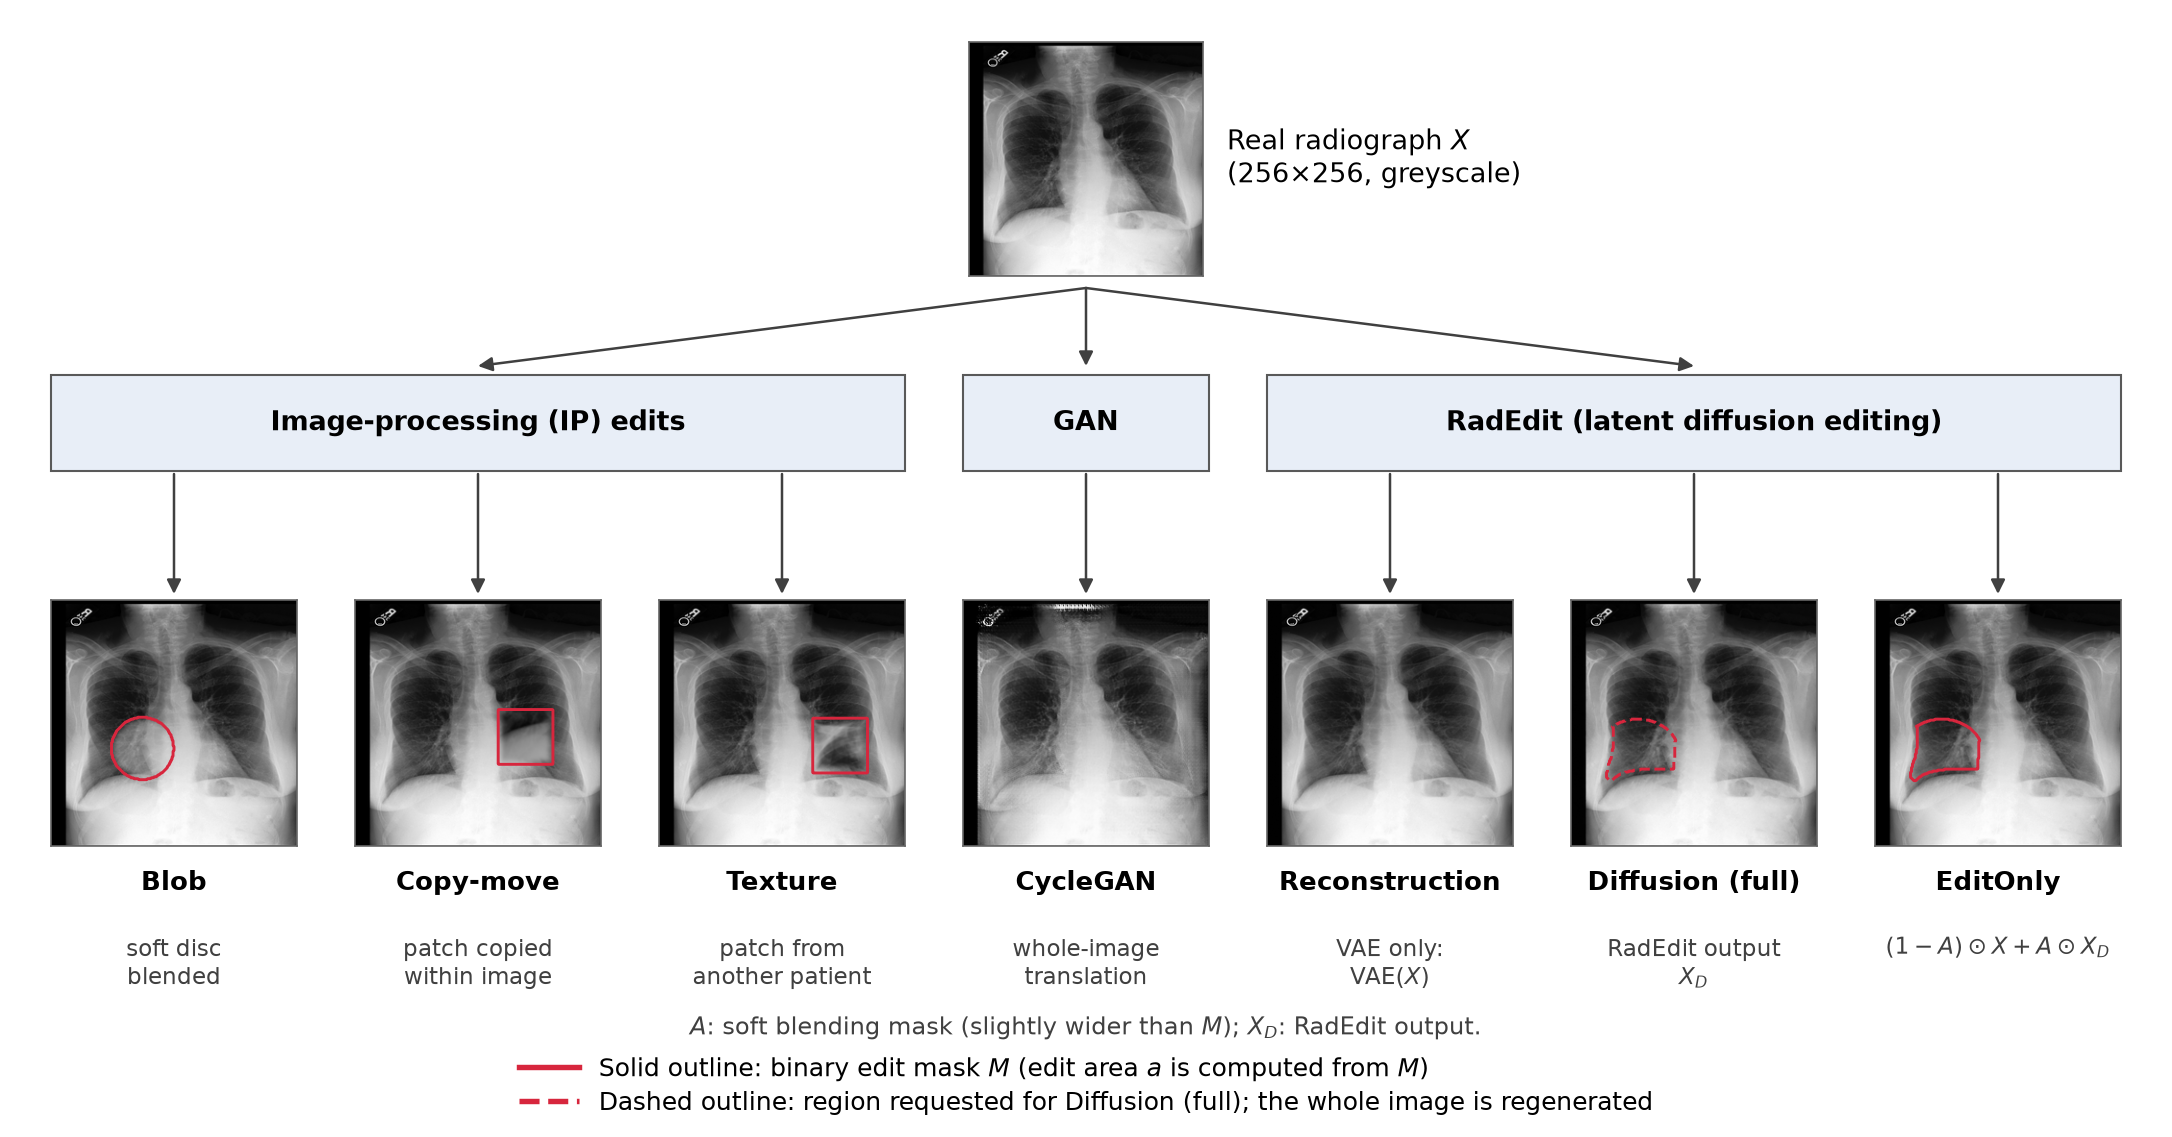

fig_gallery


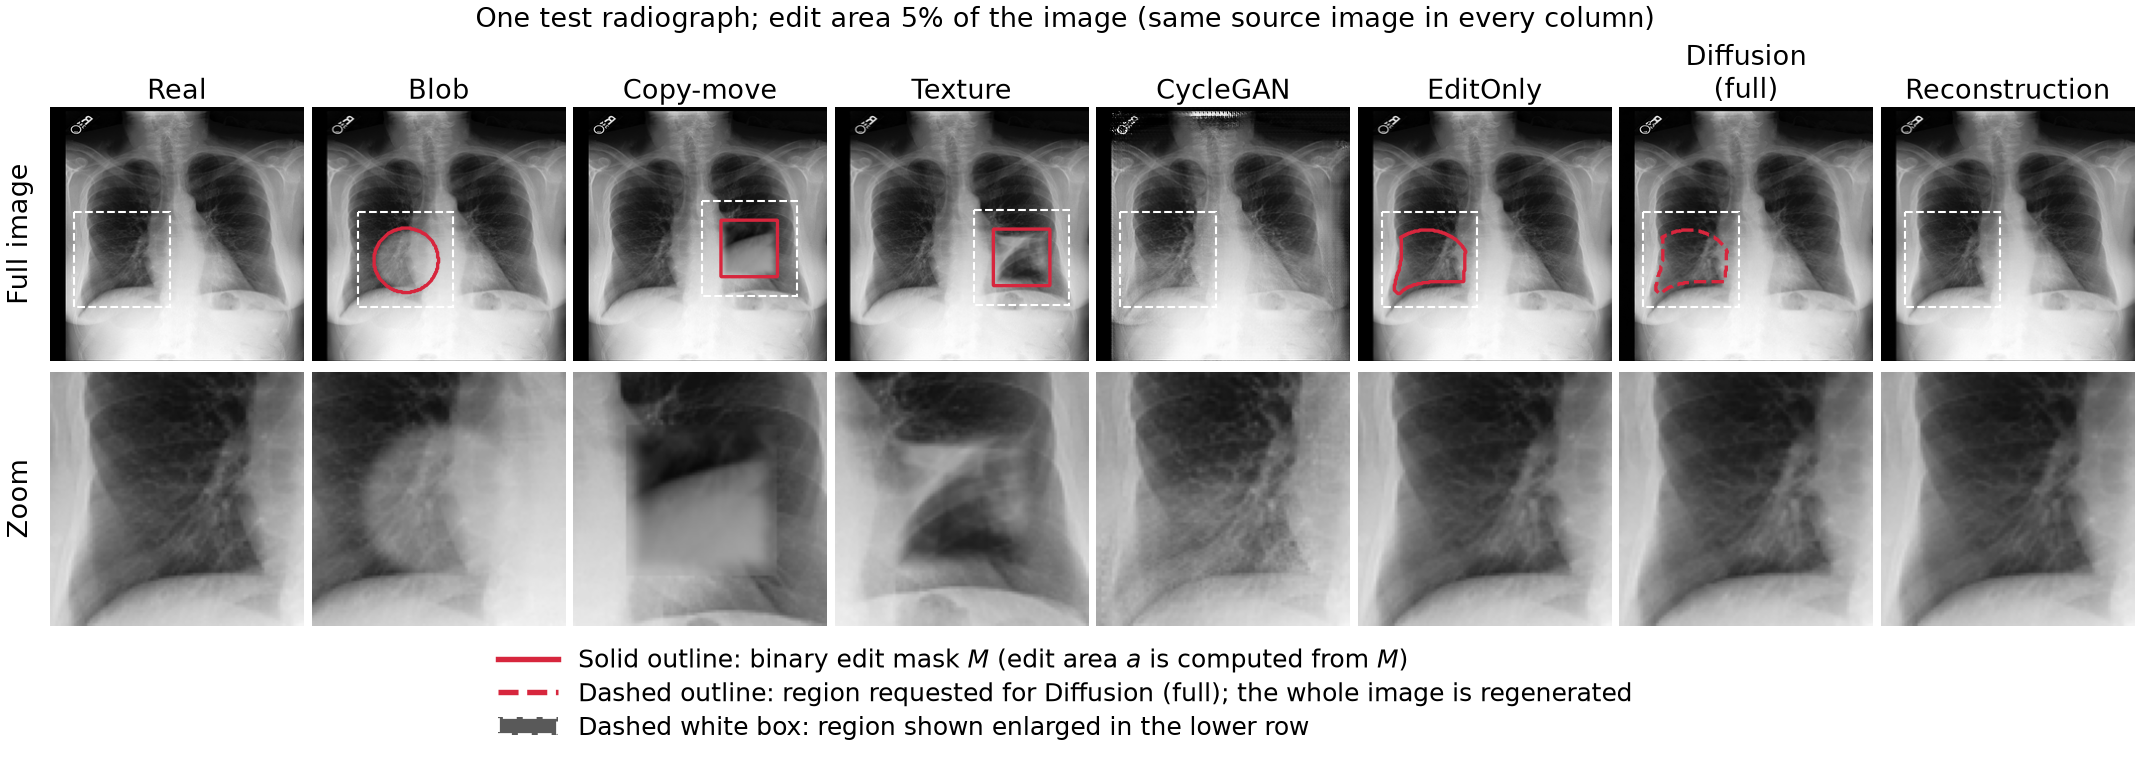

fig_vae_trace


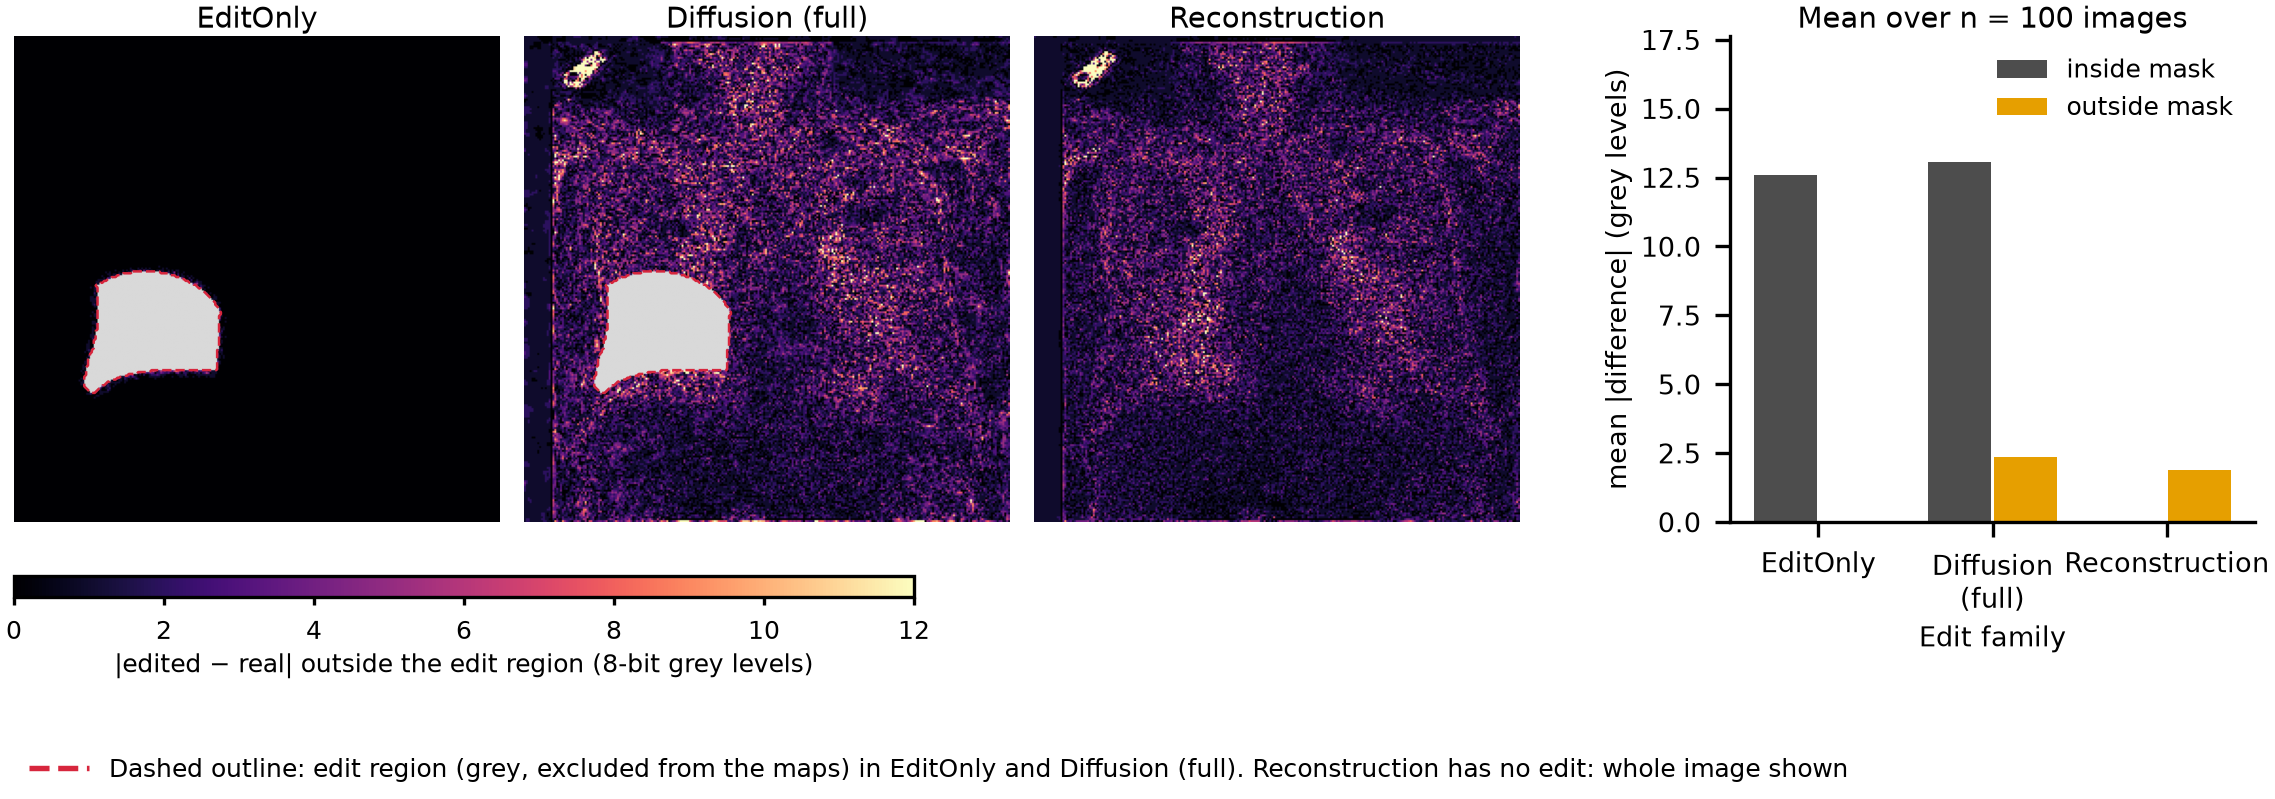

fig_ladder_crops


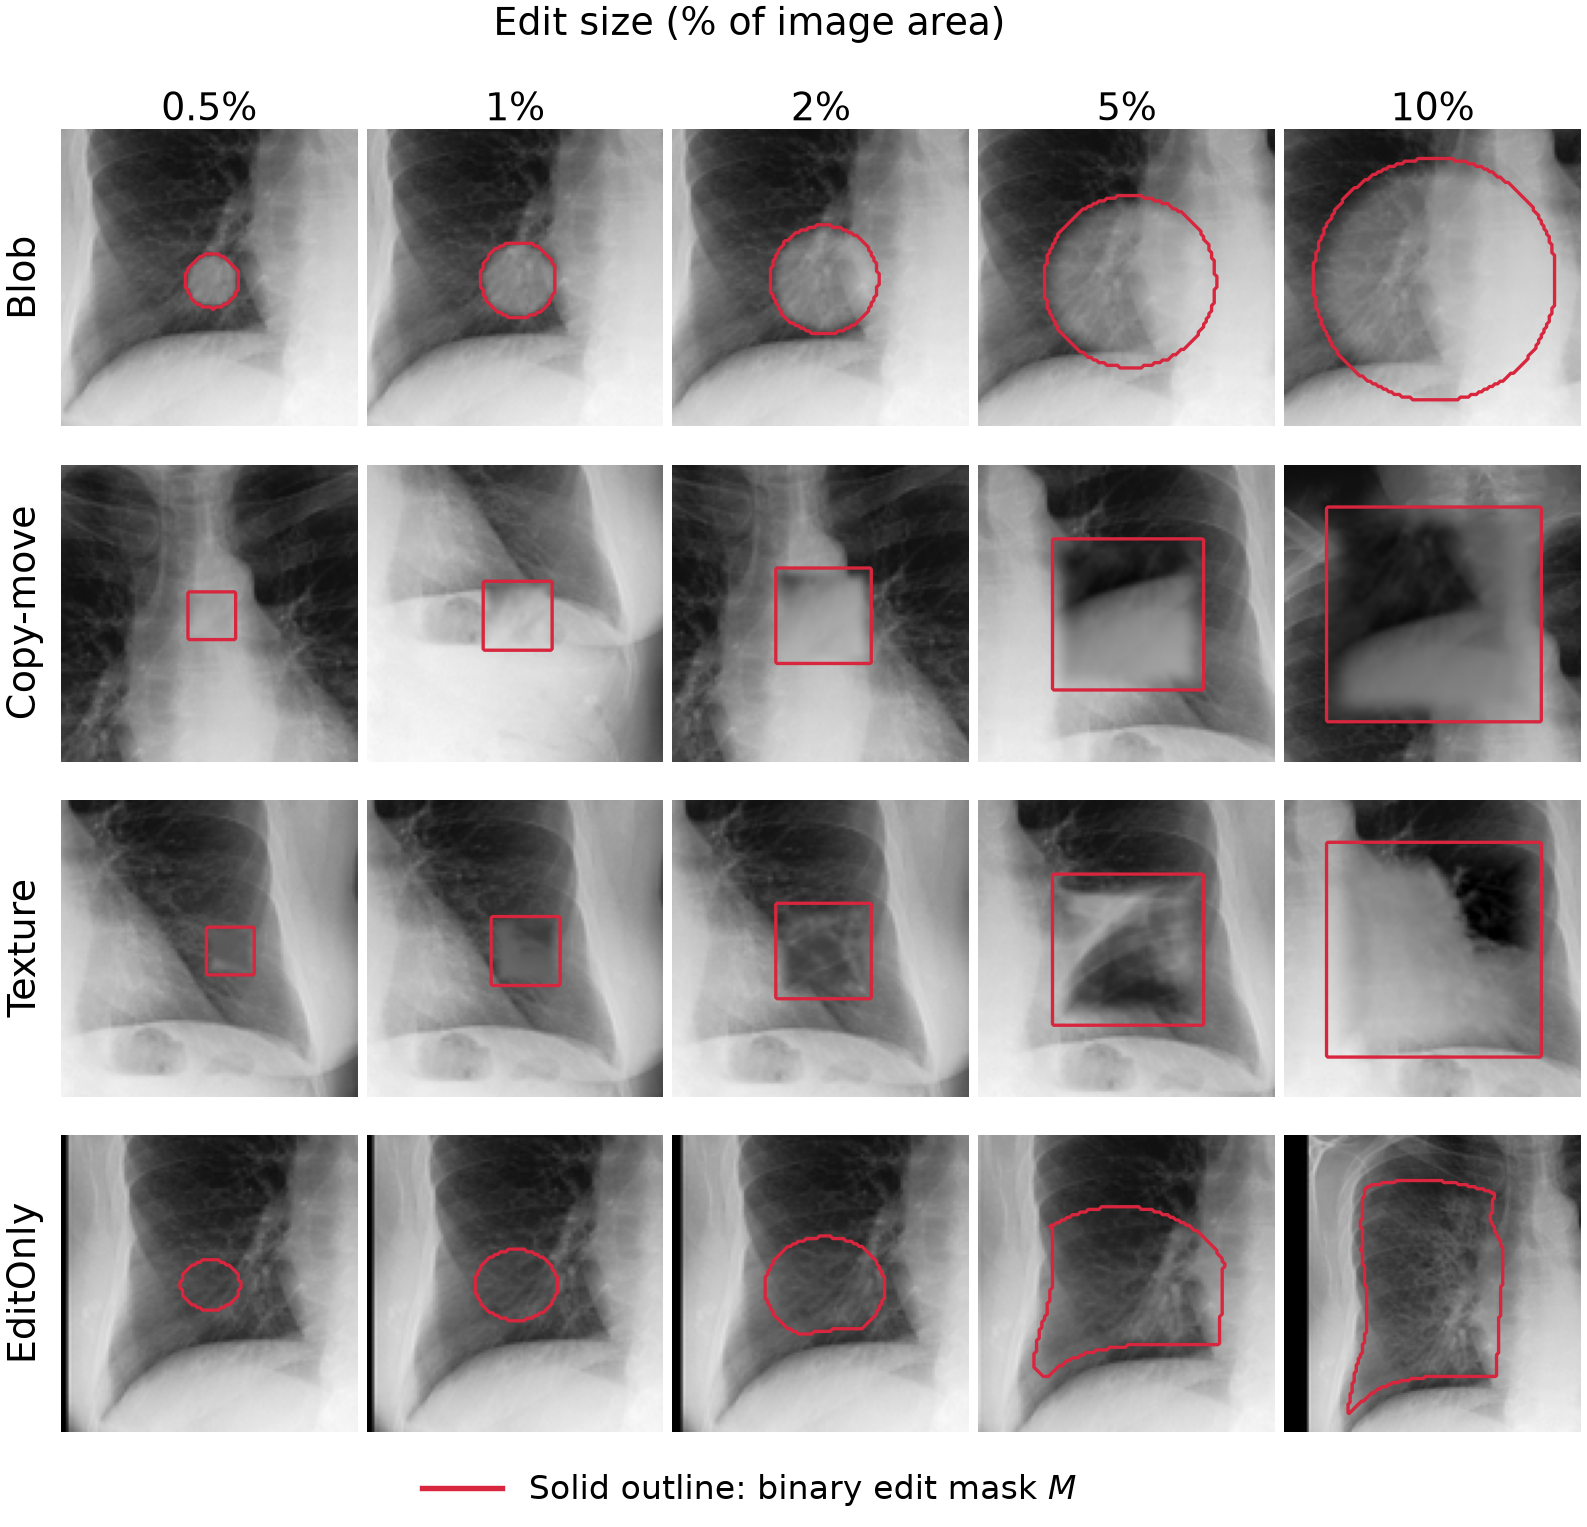

fig_ladder_full


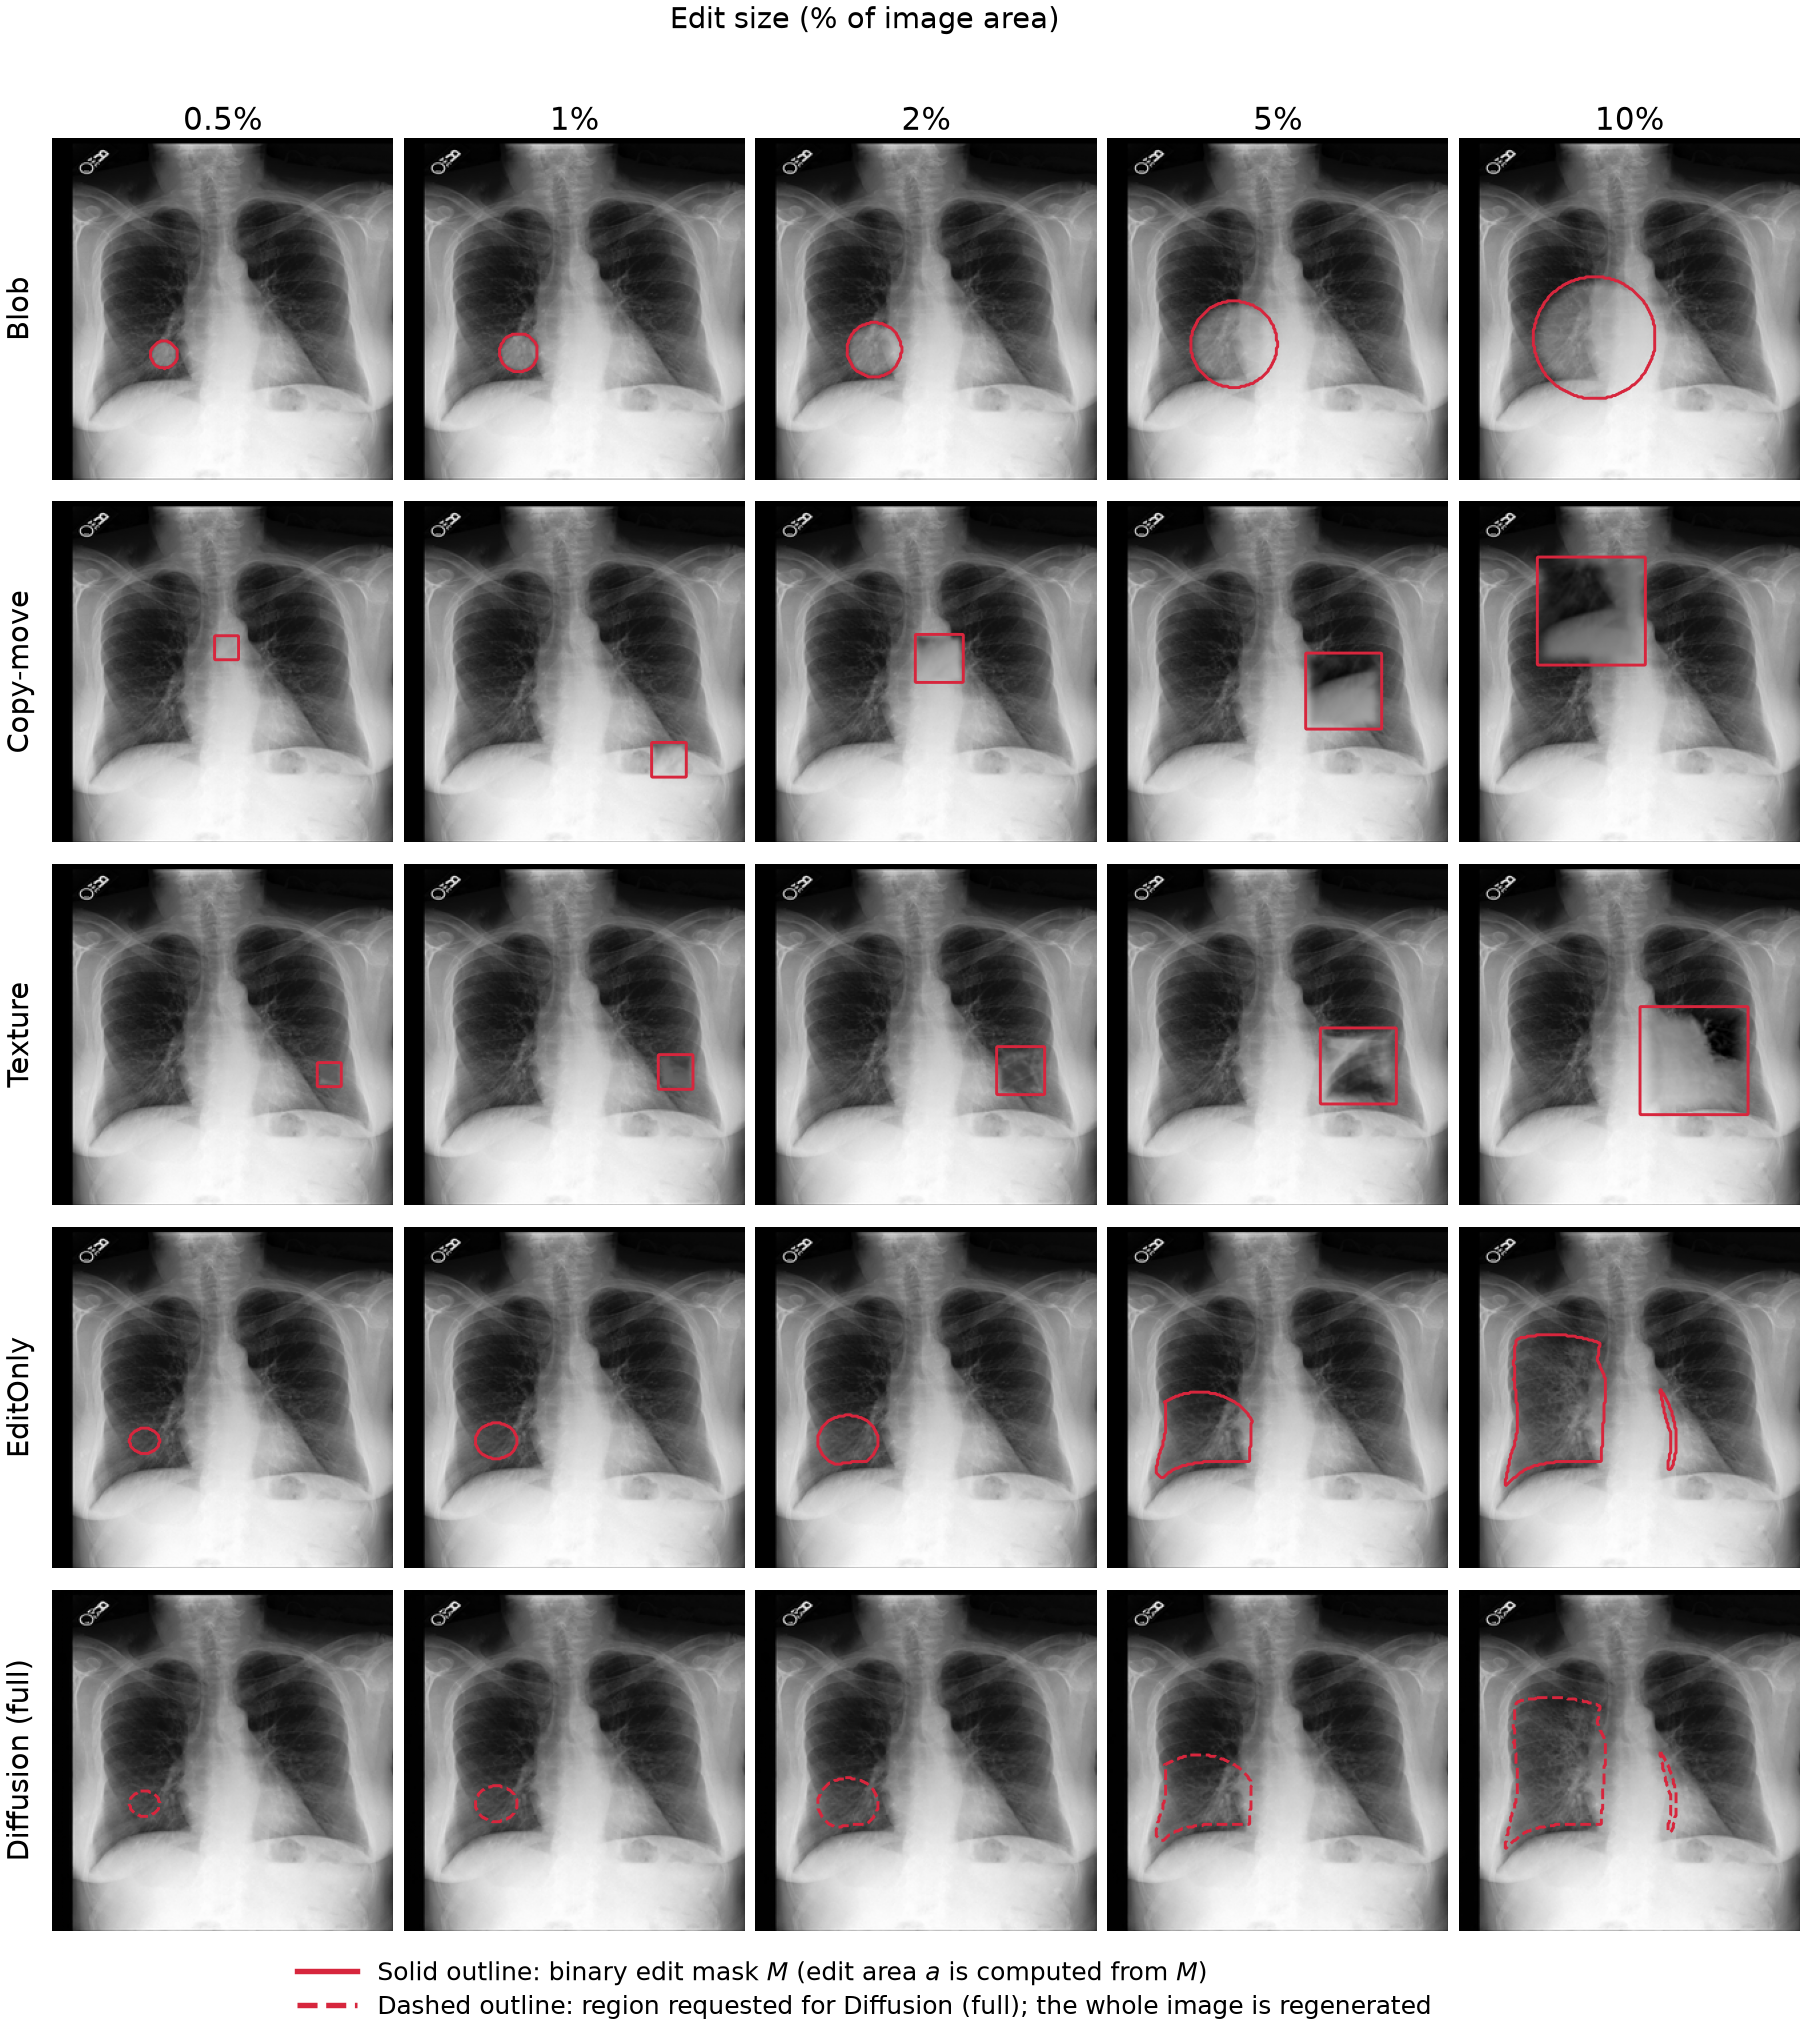

In [27]:
from IPython.display import display, Image

for name in ["fig_pipeline", "fig_gallery", "fig_vae_trace", "fig_ladder_crops", "fig_ladder_full"]:
    print(name)
    display(Image(filename=str(mef.OUT_DIR / f"{name}.png")))